# Dead-End Filtration

This example simulates a dead-end filtration process: a feed containing a large protein, a small salt, and water is pressed through a membrane under constant flow. The membrane retains the protein (cake filtration), while salt and water pass through.

**What we will see:**
- Cake resistance grows as protein accumulates, driving up transmembrane pressure.
- Salt and water are rejected at zero (they pass through freely).
- Auxiliary state `cake_height` is recorded alongside the primary states.

## 1. Component System

We define three components. Molar mass is given in **kg/mol**, which is numerically identical to **kDa** -- so `protein` at 1000 kg/mol = 1 MDa, and `water` at 0.018 kg/mol = 18 Da.

In [1]:
import matplotlib.pyplot as plt
from CADETPythonSimulator.componentsystem import Component, ComponentSystem

component_system = ComponentSystem(
    [
        Component("protein", molar_mass=1000.0, density=1100.0),  # 1 MDa, retained
        Component("salt", molar_mass=80.0, density=1100.0),  # 80 kDa, passes through
        Component(
            "water", molar_mass=0.018, density=1000.0, viscosity=0.001
        ),  # solvent
    ],
    name="filtration_system",
)

## 2. Inlet

`DistributionInlet` feeds a constant volume-fraction distribution into the system. We specify concentrations for the first two components; water fills the remaining volume.

In [2]:
from CADETPythonSimulator.distribution_base import ConstantVolumeDistribution
from CADETPythonSimulator.unit_operation import DistributionInlet

feed = ConstantVolumeDistribution(
    component_system=component_system,
    c=[1e-10, 1e-8],  # protein, salt [mol/m³]; water fills remainder
)

inlet = DistributionInlet(component_system=component_system, name="inlet")
inlet.distribution_function = feed

## 3. Dead-End Filter

The `StepCutOff` rejection model retains all species with molar mass >= `cutoff_weight`. Here, `cutoff_weight=160` kg/mol retains the protein (1000 kg/mol) and passes salt (80 kg/mol) and water.

`specific_cake_resistances` [m/kg] are model parameters -- not species properties -- because they depend on the membrane and operating conditions.

In [3]:
from CADETPythonSimulator.rejection import StepCutOff
from CADETPythonSimulator.unit_operation import DeadEndFiltration
from CADETPythonSimulator.viscosity import LogarithmicMixingViscosity

membrane = DeadEndFiltration(
    component_system=component_system,
    name="membrane",
    rejection_model=StepCutOff(cutoff_weight=160.0),  # [kg/mol = kDa]
    viscosity_model=LogarithmicMixingViscosity(),
    membrane_area=1.0,  # [m²]
    membrane_resistance=1.0,  # [m⁻¹]
    specific_cake_resistances=[1e6, 1e6, 0],  # [m/kg] per component
)

## 4. System and Initial Conditions

In [4]:
from CADETPythonSimulator.distribution_base import ConstantConcentrationDistribution
from CADETPythonSimulator.system import FlowSystem

system = FlowSystem(unit_operations=[inlet, membrane])
system.initialize_state()

# Start with a nearly empty permeate tank
empty = ConstantConcentrationDistribution(component_system=component_system, c=[0, 0])
system.states["membrane"]["permeate_tank"]["V"] = 1e-9
system.states["membrane"]["permeate_tank"]["c"] = empty.get_distribution(0, 0)

## 5. Solve

We run a single section from t=0 to t=11 s, with a constant flow connection from inlet to membrane at 1 m³/s.

In [5]:
from CADETPythonSimulator.solver import Solver

solver = Solver(
    system,
    [{"start": 0, "end": 11, "connections": [("inlet", "membrane", 1)]}],
)
solver.solve()

t = solver.time_solutions
sol = solver.unit_solutions["membrane"]
print(f"Solved {len(t)} time points from t={t[0]:.1f} to t={t[-1]:.1f} s")

Solved 12 time points from t=0.0 to t=11.0 s


## 6. Results

All output is structured as `unit_solutions[unit][state][entry]`, returning an `xr.DataArray` with dimensions `(time, component?)`. Component coordinates carry the species names.

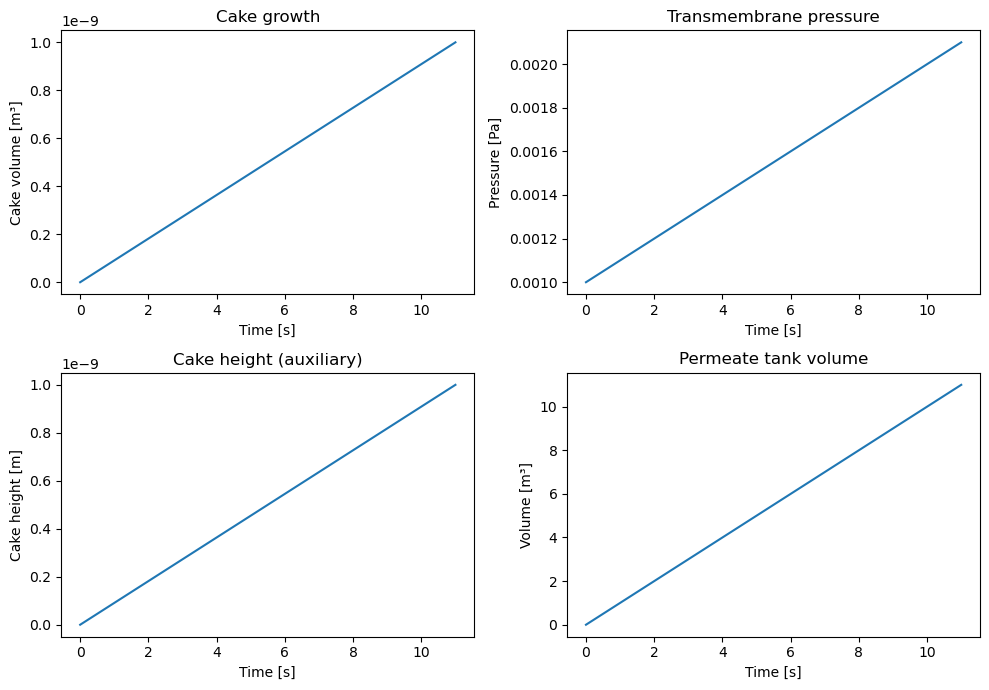

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

# ── Cake volume ───────────────────────────────────────────────────────────────
ax = axes[0, 0]
V_cake = sol["cake"]["V"]
ax.plot(t, V_cake.values)
ax.set_xlabel("Time [s]")
ax.set_ylabel("Cake volume [m³]")
ax.set_title("Cake growth")

# ── Transmembrane pressure ────────────────────────────────────────────────────
ax = axes[0, 1]
pressure = sol["cake"]["pressure"]
ax.plot(t, pressure.values)
ax.set_xlabel("Time [s]")
ax.set_ylabel("Pressure [Pa]")
ax.set_title("Transmembrane pressure")

# ── Cake height (auxiliary state) ─────────────────────────────────────────────
ax = axes[1, 0]
cake_height = sol["cake_aux"]["cake_height"]
ax.plot(t, cake_height.values)
ax.set_xlabel("Time [s]")
ax.set_ylabel("Cake height [m]")
ax.set_title("Cake height (auxiliary)")

# ── Permeate tank volume ──────────────────────────────────────────────────────
ax = axes[1, 1]
V_tank = sol["permeate_tank"]["V"]
ax.plot(t, V_tank.values)
ax.set_xlabel("Time [s]")
ax.set_ylabel("Volume [m³]")
ax.set_title("Permeate tank volume")

fig.tight_layout()
plt.show()

Component coordinates: ['protein' 'salt' 'water']


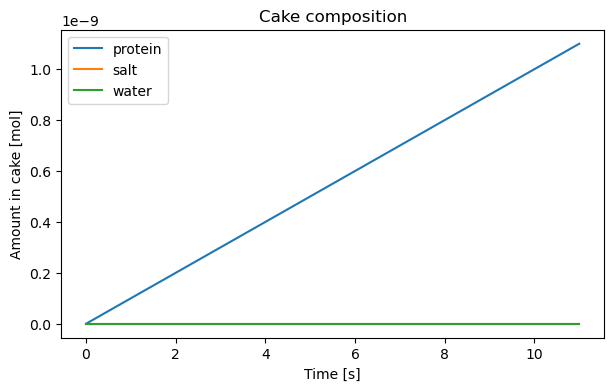

In [7]:
# Component amounts in cake over time
n_cake = sol["cake"]["n"]
print("Component coordinates:", n_cake.coords["component"].values)

fig, ax = plt.subplots(figsize=(7, 4))
for comp in n_cake.coords["component"].values:
    ax.plot(t, n_cake.sel(component=comp).values, label=comp)
ax.set_xlabel("Time [s]")
ax.set_ylabel("Amount in cake [mol]")
ax.set_title("Cake composition")
ax.legend()
plt.show()